In [129]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


## Inspecting


In [130]:
data = pd.read_csv("C:/Users/Radha/OneDrive/Desktop/FBS/Data Analysis/space_travellers.csv")
data.head()

,#,Name,Nationality,Date,Flight
0,1,Yuri Gagarin,Soviet Union,1961-04-12,Vostok 1
1,2,Alan Shepard,United States,1961-05-05,Freedom 7
2,3,Virgil Grissom,United States,1961-07-21,Liberty Bell 7
3,4,Gherman Titov,Soviet Union,1961-08-06,Vostok 2
4,5,John Glenn,United States,1962-02-20,Friendship 7


In [131]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 643 entries, 0 to 642
Data columns (total 5 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   #            643 non-null    int64 
 1   Name         643 non-null    object
 2   Nationality  643 non-null    object
 3   Date         643 non-null    object
 4   Flight       643 non-null    object
dtypes: int64(1), object(4)
memory usage: 25.2+ KB


In [132]:
data.describe()

,#
count,643.000000
mean,322.000000
std,185.762393
min,1.000000
25%,161.500000
50%,322.000000
75%,482.500000
max,643.000000


In [133]:
data.head() #first five recordes


,#,Name,Nationality,Date,Flight
0,1,Yuri Gagarin,Soviet Union,1961-04-12,Vostok 1
1,2,Alan Shepard,United States,1961-05-05,Freedom 7
2,3,Virgil Grissom,United States,1961-07-21,Liberty Bell 7
3,4,Gherman Titov,Soviet Union,1961-08-06,Vostok 2
4,5,John Glenn,United States,1962-02-20,Friendship 7


In [134]:
data.tail()

,#,Name,Nationality,Date,Flight
638,639,Gui Haichao,China,2023-05-30,Shenzhou 16
639,640,Jasmin Moghbeli,United States,2023-08-26,SpaceX Crew-7
640,641,Konstantin Borisov,Russia,2023-08-26,SpaceX Crew-7
641,642,Nikolai Chub,Russia,2023-09-15,Soyuz MS-24
642,643,Loral O'Hara,United States,2023-09-15,Soyuz MS-24


In [135]:
data.columns

Index(['#', 'Name', 'Nationality', 'Date', 'Flight'], dtype='object')

In [136]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 643 entries, 0 to 642
Data columns (total 5 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   #            643 non-null    int64 
 1   Name         643 non-null    object
 2   Nationality  643 non-null    object
 3   Date         643 non-null    object
 4   Flight       643 non-null    object
dtypes: int64(1), object(4)
memory usage: 25.2+ KB


  ### inspecting
1. 643 recored : 0 to 642 indexing
2. 5 columns
3. 44 nationalities
4. 5 colums - 1 # datatype int - serial number assigned to each record 2 Name - dataype object - name of the person who trablled to space 3 nationality - object - country or national identity recorded for the traveller 4 Date - object - date associated with the recorded spaceflight 5 flight - object - name or designation of the spacecraft / mission
5. 0 missing values

In [137]:
data.isnull().sum() 

#              0
Name           0
Nationality    0
Date           0
Flight         0
dtype: int64

no missing values are present in the database

In [138]:
data.duplicated().sum()

0

In [139]:
data.nunique()

#              643
Name           643
Nationality     44
Date           313
Flight         314
dtype: int64

In [140]:
data['Flight'].duplicated().sum()

329

In [141]:
type(data)

pandas.core.frame.DataFrame

In [142]:
data.dtypes

#               int64
Name           object
Nationality    object
Date           object
Flight         object
dtype: object

In [143]:
data['Date'] = pd.to_datetime(data['Date'])

In [144]:
data.dtypes

#                       int64
Name                   object
Nationality            object
Date           datetime64[ns]
Flight                 object
dtype: object

In [145]:
data['Year'] = data['Date'].dt.year
data['Year']

0      1961
1      1961
2      1961
3      1961
4      1962
       ... 
638    2023
639    2023
640    2023
641    2023
642    2023
Name: Year, Length: 643, dtype: int32

In [146]:
data['Month'] = data['Date'].dt.month
data['Month']

0      4
1      5
2      7
3      8
4      2
      ..
638    5
639    8
640    8
641    9
642    9
Name: Month, Length: 643, dtype: int32

In [147]:
data['Month_Name'] = data['Date'].dt.month_name()
data['Month_Name']

0          April
1            May
2           July
3         August
4       February
         ...    
638          May
639       August
640       August
641    September
642    September
Name: Month_Name, Length: 643, dtype: object

In [148]:
data['Decade'] = (data['Year']//10)*10
data['Decade']

0      1960
1      1960
2      1960
3      1960
4      1960
       ... 
638    2020
639    2020
640    2020
641    2020
642    2020
Name: Decade, Length: 643, dtype: int32

In [149]:
data.head()

,#,Name,Nationality,Date,Flight,Year,Month,Month_Name,Decade
0,1,Yuri Gagarin,Soviet Union,1961-04-12,Vostok 1,1961,4,April,1960
1,2,Alan Shepard,United States,1961-05-05,Freedom 7,1961,5,May,1960
2,3,Virgil Grissom,United States,1961-07-21,Liberty Bell 7,1961,7,July,1960
3,4,Gherman Titov,Soviet Union,1961-08-06,Vostok 2,1961,8,August,1960
4,5,John Glenn,United States,1962-02-20,Friendship 7,1962,2,February,1960


##added year, month , month_name and decade to make historical anyalysis easier

In [150]:
data['Date'].min()

Timestamp('1961-04-12 00:00:00')

In [151]:
data['Date'].max()

Timestamp('2023-09-15 00:00:00')

In [152]:
data['Date'].isnull().sum()

0

In [153]:
data['Name'] = data['Name'].str.strip()
data['Nationality'] = data['Nationality'].str.strip()
data['Flight'] = data['Flight'].str.strip()
data['Name']
data['Nationality']
data['Flight']   # to remove unwanted leading trailing spaces from text col.

0            Vostok 1
1           Freedom 7
2      Liberty Bell 7
3            Vostok 2
4        Friendship 7
            ...      
638       Shenzhou 16
639     SpaceX Crew-7
640     SpaceX Crew-7
641       Soyuz MS-24
642       Soyuz MS-24
Name: Flight, Length: 643, dtype: object


1. we analyze nationality , year, decade, month and flight records to understand their individeual distribution


## Nationality Distiributionn

In [154]:
data['Nationality'].value_counts()

Nationality
United States           391
Soviet Union             72
Russia                   62
China                    18
Japan                    14
Canada                   12
France                   10
Germany                   8
Italy                     7
United Kingdom            4
West Germany              3
Saudi Arabia              3
Netherlands               3
Bulgaria                  2
United Arab Emirates      2
Belgium                   2
Brazil                    2
Israel                    2
Portugal                  1
Australia                 1
Kazakhstan                1
South Africa              1
Denmark                   1
Spain                     1
Sweden                    1
Malaysia                  1
South Korea               1
Slovakia                  1
Austria                   1
Ukraine                   1
Switzerland               1
Afghanistan               1
Syria                     1
Mexico                    1
India                     1
Romania 

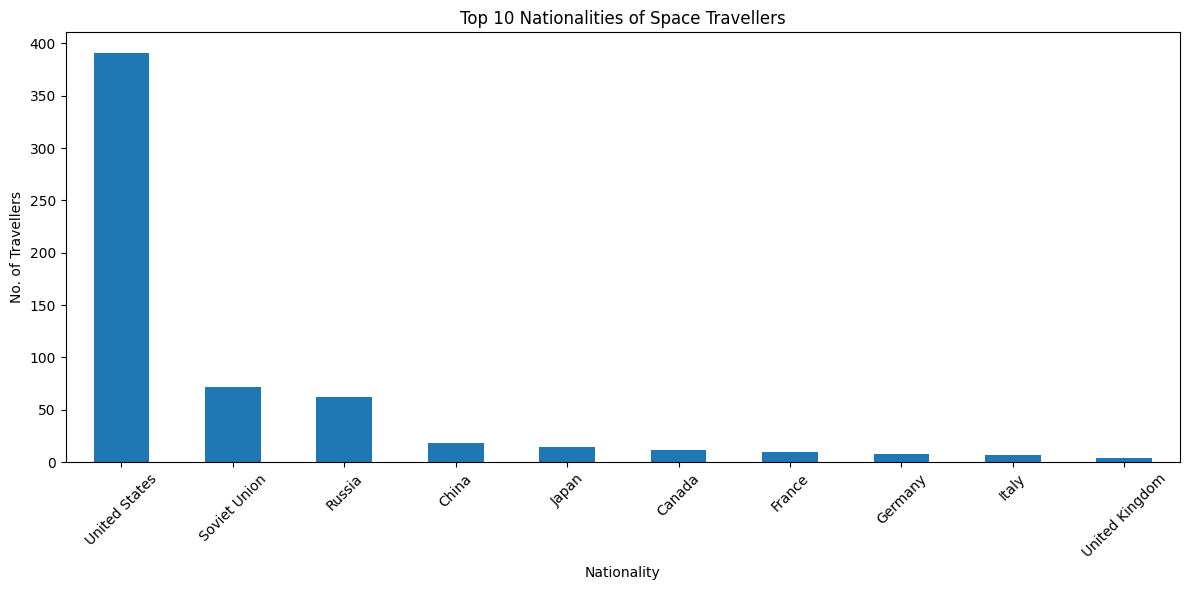

In [155]:
plt.figure(figsize=(12,6))
data['Nationality'].value_counts().head(10).plot(kind='bar')
plt.title('Top 10 Nationalities of Space Travellers')
plt.xlabel('Nationality')
plt.ylabel('No. of Travellers')
plt.xticks(rotation= 45)
plt.tight_layout()
plt.show()

## year distribution

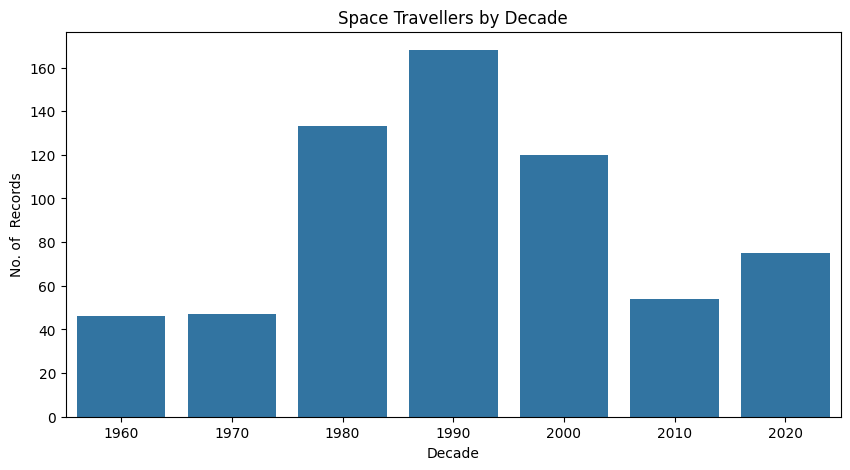

In [156]:
decade_count = data['Decade'].value_counts().sort_index()
plt.figure(figsize= (10,5))
sns.barplot(x= decade_count.index, y = decade_count.values)
plt.title('Space Travellers by Decade')
plt.xlabel('Decade')
plt.ylabel('No. of  Records')
plt.show()

## Month Distribution

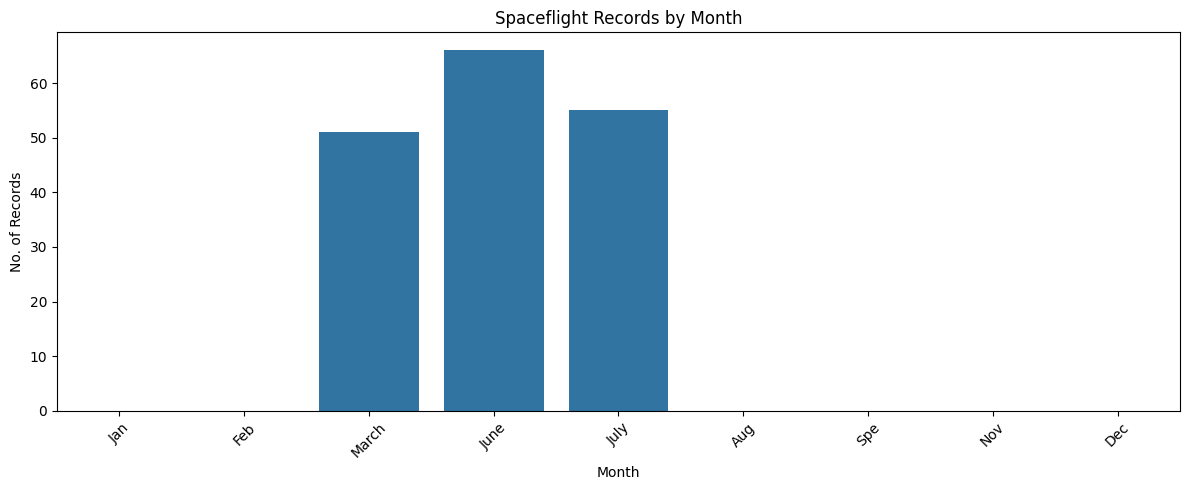

In [157]:
month_order = [ 'Jan', 'Feb', 'March', 'June', 'July', 'Aug', 'Spe', 'Nov', 'Dec']
month_count = data['Month_Name'].value_counts().reindex(month_order)
plt.figure(figsize=(12,5))
sns.barplot(x = month_count.index, y = month_count.values)
plt.title('Spaceflight Records by Month')
plt.xlabel('Month')
plt.ylabel('No. of Records')
plt.xticks(rotation= 45)
plt.tight_layout()
plt.show()


## Top 10 flights

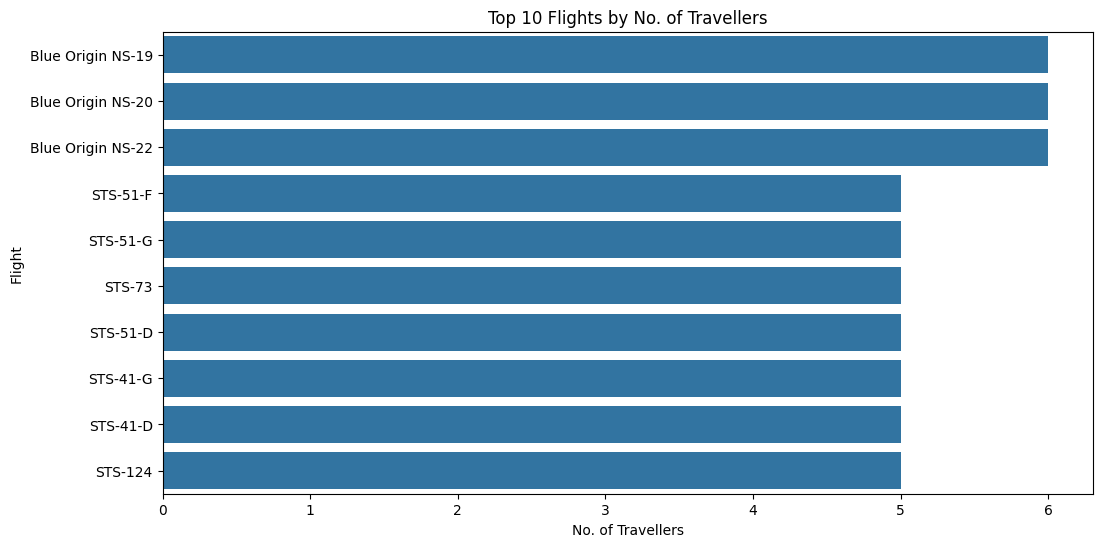

In [158]:
flight_count = data['Flight'].value_counts().head(10)
plt.figure(figsize=(12,6))
sns.barplot(x = flight_count.values, y = flight_count.index)
plt.title('Top 10 Flights by No. of Travellers')
plt.xlabel('No. of Travellers')
plt.ylabel('Flight')
plt.show()


1. compare nationality with decade, year with traveller count, and flight with traveller count

## nationality vs decade

In [159]:
country_decade = pd.crosstab( data['Decade'], data['Nationality'])
top_countries = data['Nationality'].value_counts().head(5).index
country_decade = country_decade[top_countries]
country_decade

Nationality,United States,Soviet Union,Russia,China,Japan
Decade,,,,,
1960,25,21,0,0,0
1970,19,24,0,0,0
1980,93,22,0,0,0
1990,111,5,19,0,5
2000,86,0,13,6,2
2010,17,0,18,5,5
2020,40,0,12,7,2


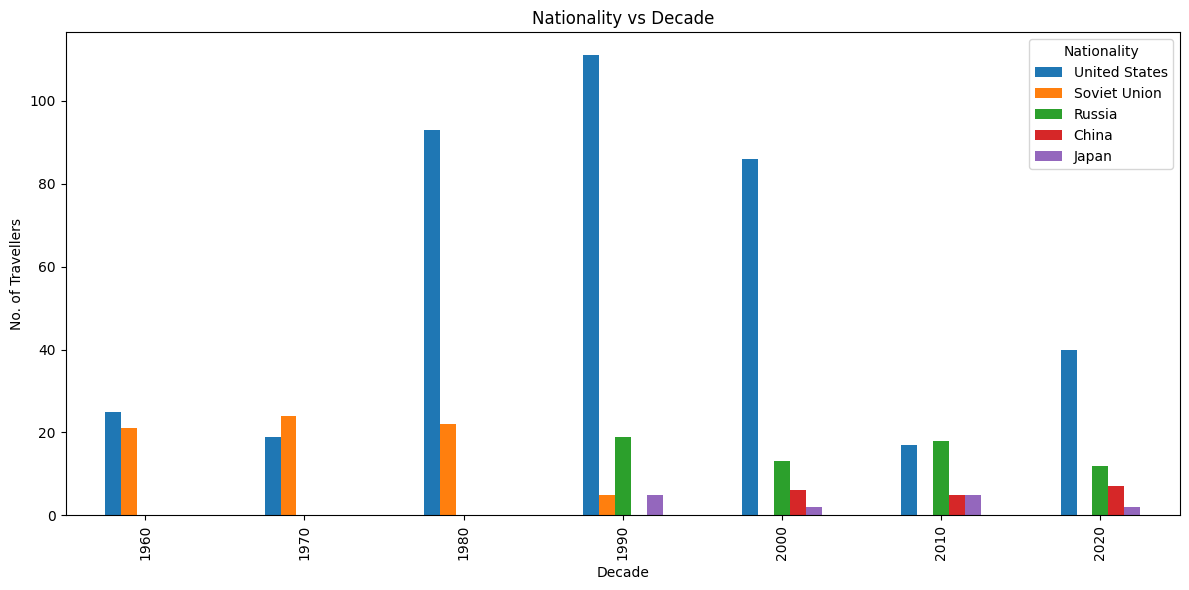

In [160]:
country_decade.plot( kind = 'bar', figsize = (12,6))
plt.title('Nationality vs Decade')
plt.xlabel('Decade')
plt.ylabel('No. of Travellers')
plt.legend(title= 'Nationality')
plt.tight_layout()
plt.show()

## year vs No. of travellers

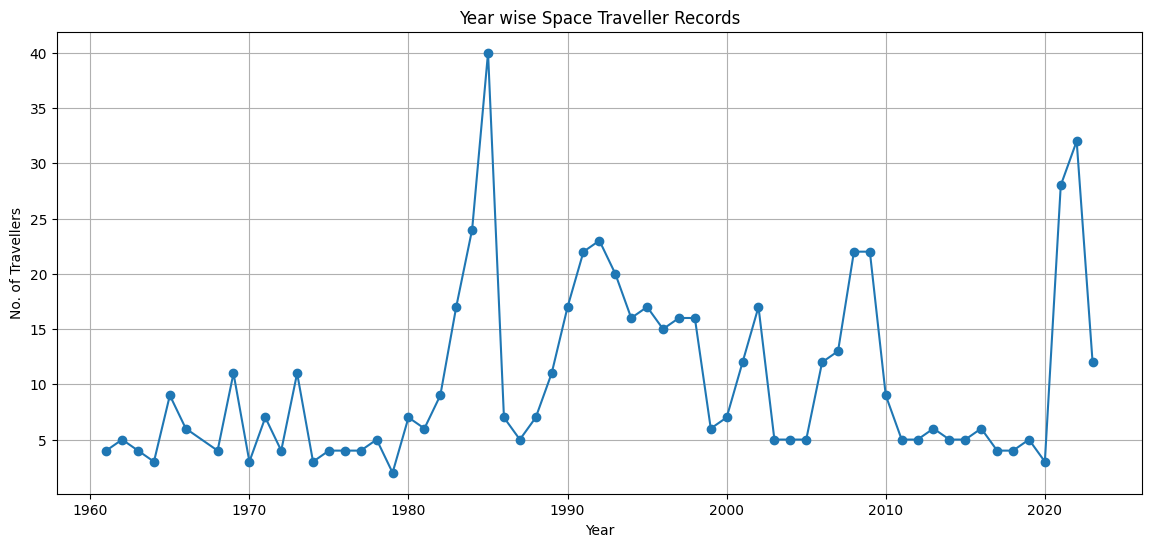

In [161]:
year_count = data['Year'].value_counts().sort_index()
plt.figure(figsize=(14,6))
plt.plot(year_count.index, year_count.values, marker = 'o')
plt.title('Year wise Space Traveller Records')
plt.xlabel('Year')
plt.ylabel('No. of Travellers')
plt.grid()
plt.show()

In [162]:
year_count.sort_values(ascending=False).head(10)

Year
1985    40
2022    32
2021    28
1984    24
1992    23
2009    22
2008    22
1991    22
1993    20
1983    17
Name: count, dtype: int64

## flight vs No. of travellers

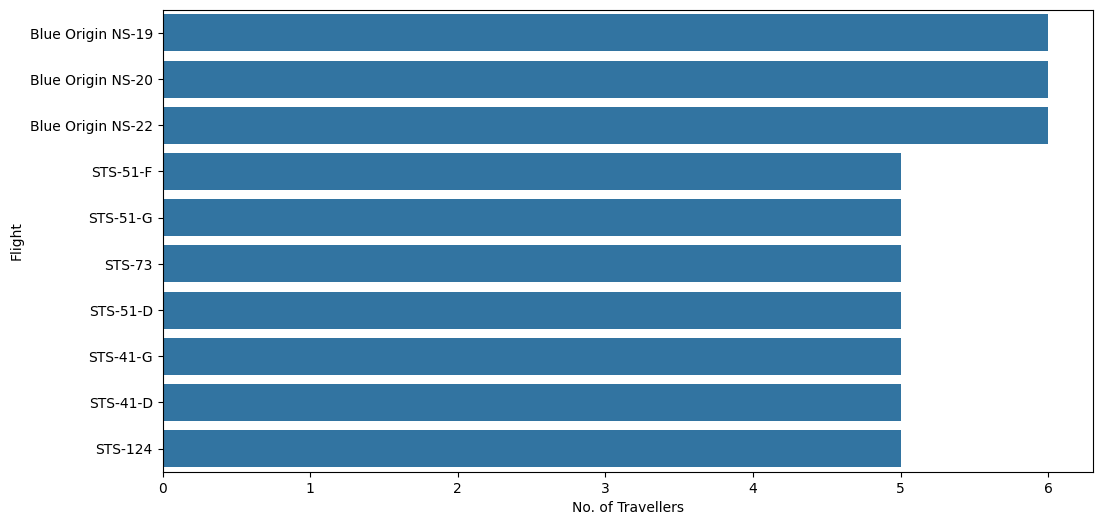

In [163]:
flight_people= data['Flight'].value_counts().head(10)
plt.figure(figsize=(12, 6))
sns.barplot( x = flight_people.values, y = flight_people.index)
plt.xlabel('No. of Travellers')
plt.ylabel('Flight')
plt.show()

## Narionality vs year

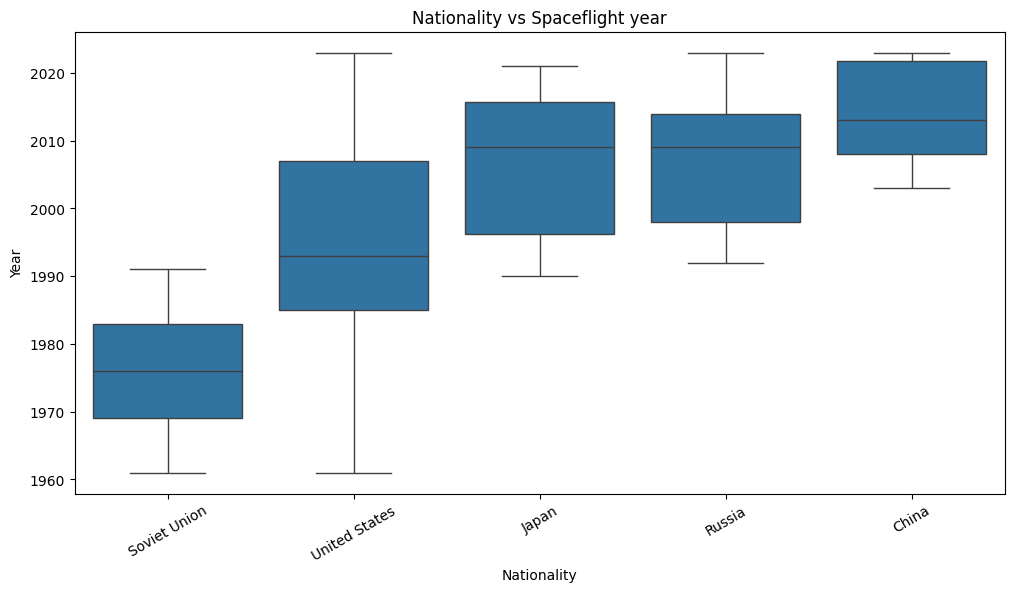

In [164]:
top_5 = data['Nationality'].value_counts().head(5).index
filtered_data = data[data['Nationality'].isin(top_5)]
plt.figure(figsize=(12,6))
sns.boxplot( data = filtered_data, x = 'Nationality', y = 'Year')
plt.title('Nationality vs Spaceflight year')
plt.xticks(rotation= 30)
plt.show()


1. analyze nationality , decade and traveller count together

### Nationality , decade and traveller count 

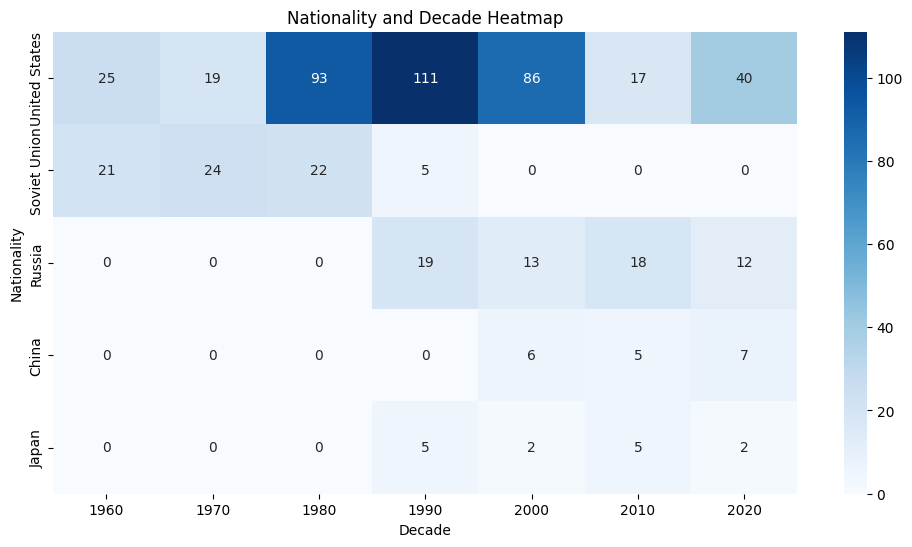

In [165]:
plt.figure(figsize=(12,6))
sns.heatmap( country_decade.T, annot = True, fmt ='d', cmap='Blues')
plt.title('Nationality and Decade Heatmap')
plt.xlabel('Decade')
plt.ylabel('Nationality')
plt.show()

### flight and nationaluty relationship

In [166]:
flight_nationality = pd.crosstab( data['Flight'], data['Nationality'])
flight_nationality['Total'] = flight_nationality.sum(axis = 1)
flight_nationality.sort_values(by = 'Total', ascending = False).head(10)

Nationality,Afghanistan,Australia,Austria,Belgium,Brazil,Bulgaria,Canada,China,Cuba,Czechoslovakia,...,Sweden,Switzerland,Syria,Ukraine,United Arab Emirates,United Kingdom,United States,Vietnam,West Germany,Total
Flight,,,,,,,,,,,,,,,,,,,,,
Blue Origin NS-22,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,1,3,0,0,6
Blue Origin NS-20,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,6,0,0,6
Blue Origin NS-19,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,6,0,0,6
STS-51-G,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,3,0,0,5
STS-90,0,0,0,0,0,0,1,0,0,0,...,0,0,0,0,0,0,4,0,0,5
STS-51-D,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,5,0,0,5
STS-61-B,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,4,0,0,5
STS-41-G,0,0,0,0,0,0,1,0,0,0,...,0,0,0,0,0,0,4,0,0,5
Blue Origin NS-21,0,0,0,0,1,0,0,0,0,0,...,0,0,0,0,0,1,3,0,0,5


### travellere count by year and nationality

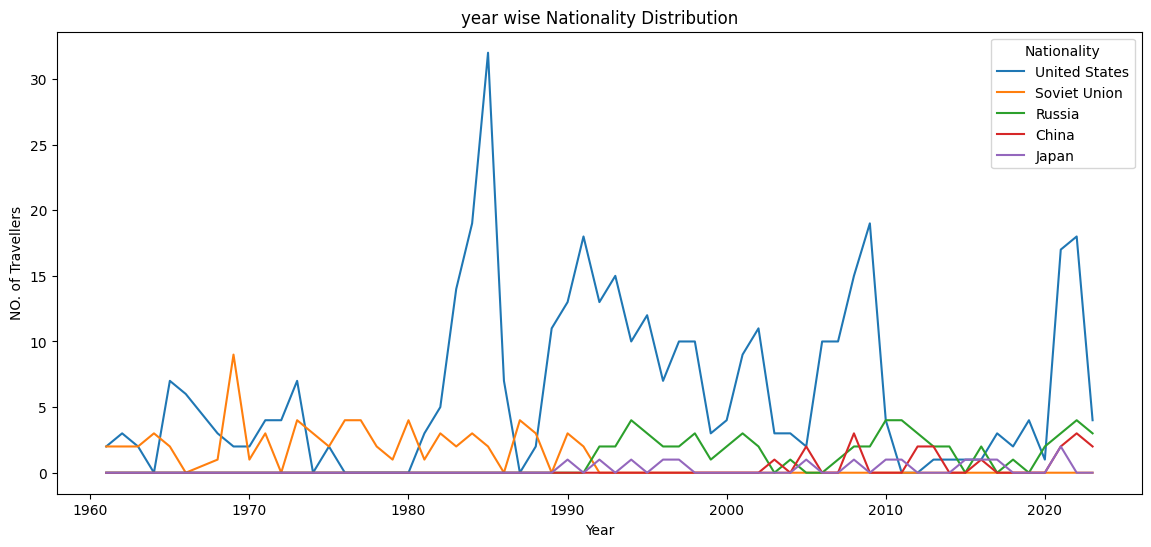

In [167]:
year_nationality = pd.crosstab(data['Year'], data['Nationality'])
year_nationality[top_countries].plot(figsize=(14,6))
plt.title('year wise Nationality Distribution')
plt.xlabel('Year')
plt.ylabel('NO. of Travellers')
plt.show()

## Outlierrs detection
1. IQR = Q3- Q1
2. lb = Q1 - 1.5* IQR
3. ub = Q3 +1.5 *IQR

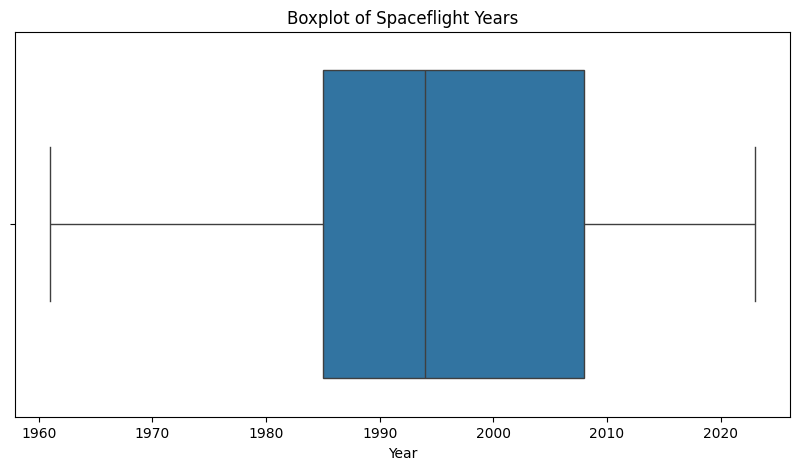

In [168]:
plt.figure(figsize=(10,5))
sns.boxplot(x = data['Year'])
plt.title('Boxplot of Spaceflight Years')
plt.xlabel('Year')
plt.show()

In [169]:
q1 = data['Year'].quantile(0.25)
q3 = data['Year'].quantile(0.75)
IQR = q3- q1
lb = q1 - 1.5 * IQR
ub = q3 + 1.5 * IQR
print('Q1:', q1)
print('Q3:', q3)
print('IQR:', IQR)
print('Lower Bound:', lb)
print('Upper Bound:', ub)

Q1: 1985.0
Q3: 2008.0
IQR: 23.0
Lower Bound: 1950.5
Upper Bound: 2042.5


In [170]:
outliers = data[(data['Year']< lb) | (data['Year']> ub)]
outliers[['Name', 'Nationality', 'Year', 'Flight']]

,Name,Nationality,Year,Flight


## Outlier analysis  obserrvation 
the  calculated lower bound is 1950.5 and the upper bound is 2024.5 
all records within these limits. therefore , no outliers were detected in the year column using the IQR method


### Correletion analysis


In [171]:
data[['Year', 'Decade']].corr()

,Year,Decade
Year,1.000000,0.985703
Decade,0.985703,1.000000


## 1. The dataset contains 643 traveller records and 5 original columns. 
2. the united states has the highest repreesentation with 391 records
3. the soviet union has 72 records, while Russia has 62 records.
4. the dataset contains 44 different nationality labels
5. the 1990s have the highest no. of traveller records with 168
6. 1985 has the highest number of recorde travellers with 40
7. bluw origin ns - 22 , ns -20 and ns-19 each have six recorded travellers
8. no missing values or completely duplicated records were identified
9. the dataset covers recorded spaceflight dated from 1961 to spe 2023
